<center><h1>Sarepaka_Abhishek_HW4</h1></center>
<br>
<br>

Name: Abhishek Sarepaka
<br>
Github Username: asarepaka
<br>
USC ID: 9325-5838-63

## 1. Time Series Classification Part 1: Feature Creation/Extraction (HW3 Rerun)

### (a) Obtain Data

Import packages

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import RFE
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score, accuracy_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score 
from sklearn.metrics import ConfusionMatrixDisplay
import statsmodels.api as sm
from sklearn.preprocessing import label_binarize
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import RocCurveDisplay
from sklearn.preprocessing import label_binarize

pd.set_option("display.max_columns", None)

Get the AReM Data Set

In [2]:
path = "/Users/abhisheksarepaka/Downloads/Homework 3, 4 Data/AReM"

ts = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]

folders = {"bending1": 7, "bending2": 6, "cycling": 15, "lying": 15,
           "sitting": 15, "standing": 15, "walking": 15}

data = []

for folder in folders:
    for i in range(1, folders[folder] + 1):
        file_path = path + "/" + folder + "/dataset" + str(i) + ".csv"

        if folder == "bending2" and i == 4:
            df = pd.read_csv(file_path, skiprows=5, header=None, usecols=range(7), sep=r"\s+")
        else:
            df = pd.read_csv(file_path, skiprows=5, header=None, usecols=range(7))

        df.columns = ["time"] + ts
        data.append([folder, i, df])

print("number of instances:", len(data))

number of instances: 88


### (b) Splitting Data

In [3]:
train = []
test = []

for inst in data:
    activity = inst[0]
    number = inst[1]

    if activity == "bending1" or activity == "bending2":
        if number <= 2:
            test.append(inst)
        else:
            train.append(inst)
    else:
        if number <= 3:
            test.append(inst)
        else:
            train.append(inst)

print("train:", len(train))
print("test:", len(test))

train: 69
test: 19


### (c) Feature Extraction

In [4]:
def get_features(data, l):
    rows = []

    for inst in data:
        df = inst[2]
        n_rows = len(df)
        row = {}

        for p in range(l):
            start = p * n_rows // l
            end = (p + 1) * n_rows // l
            part = df.iloc[start:end]

            for n in range(6):
                col = part[ts[n]]
                name = str(n + 1) + "_part" + str(p + 1)
                row["mean" + name] = col.mean()
                row["median" + name] = col.median()
                row["3rd_quart" + name] = col.quantile(0.75)

        row["activity"] = inst[0]
        rows.append(row)

    return pd.DataFrame(rows)

train_features = get_features(train, 1)
train_features.head()

,mean1_part1,median1_part1,3rd_quart1_part1,mean2_part1,median2_part1,3rd_quart2_part1,mean3_part1,median3_part1,3rd_quart3_part1,mean4_part1,median4_part1,3rd_quart4_part1,mean5_part1,median5_part1,3rd_quart5_part1,mean6_part1,median6_part1,3rd_quart6_part1,activity
0,43.954500,44.33,45.00,0.426250,0.47,0.50,22.122354,23.000,24.0000,0.497312,0.43,0.83,35.588458,36.00,36.50,0.493292,0.43,0.94,bending1
1,42.179812,43.50,45.00,0.696042,0.50,1.12,22.183625,23.000,24.3725,0.989917,0.83,1.30,33.493917,35.00,36.33,0.613521,0.50,1.00,bending1
2,41.678063,41.75,42.75,0.535979,0.50,0.71,19.006563,19.125,22.0625,0.841875,0.50,1.12,29.857083,30.00,31.25,0.383292,0.43,0.50,bending1
3,43.454958,43.25,45.00,0.378083,0.47,0.50,15.793333,15.000,18.2700,0.849354,0.50,1.12,23.034792,23.50,24.00,0.679646,0.50,0.87,bending1
4,43.969125,44.50,44.67,0.413125,0.47,0.50,15.868021,16.250,18.0000,0.666354,0.47,0.94,22.103750,21.67,23.75,0.555312,0.49,0.83,bending1


## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

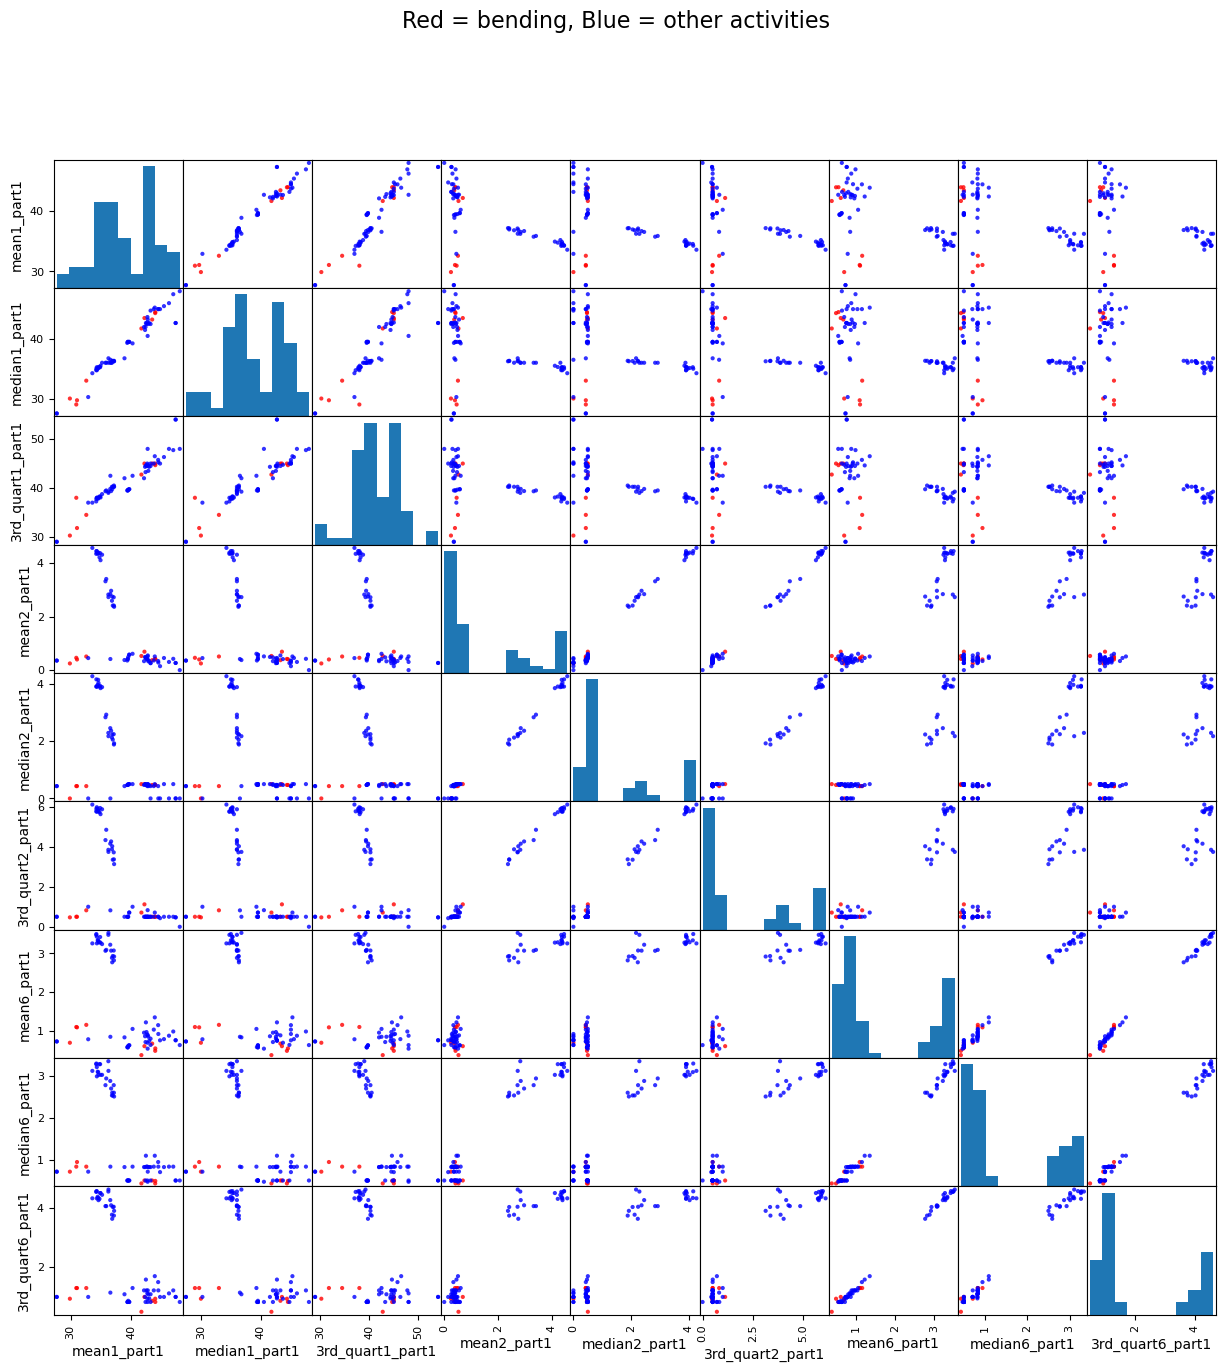

In [5]:
def get_labels(features):
    labels = []
    for a in features["activity"]:
        if a == "bending1" or a == "bending2":
            labels.append(1)
        else:
            labels.append(0)
    return np.array(labels)


train_features = get_features(train, 1)
y_train = get_labels(train_features)

cols = ["mean1_part1", "median1_part1", "3rd_quart1_part1",
        "mean2_part1", "median2_part1", "3rd_quart2_part1",
        "mean6_part1", "median6_part1", "3rd_quart6_part1"]

colors = ["red" if label == 1 else "blue" for label in y_train]

pd.plotting.scatter_matrix(train_features[cols], c=colors, figsize=(15, 15), alpha=0.8, diagonal="hist")
plt.suptitle("Red = bending, Blue = other activities", fontsize=16)
plt.show()

#### ii. Splitted Plots

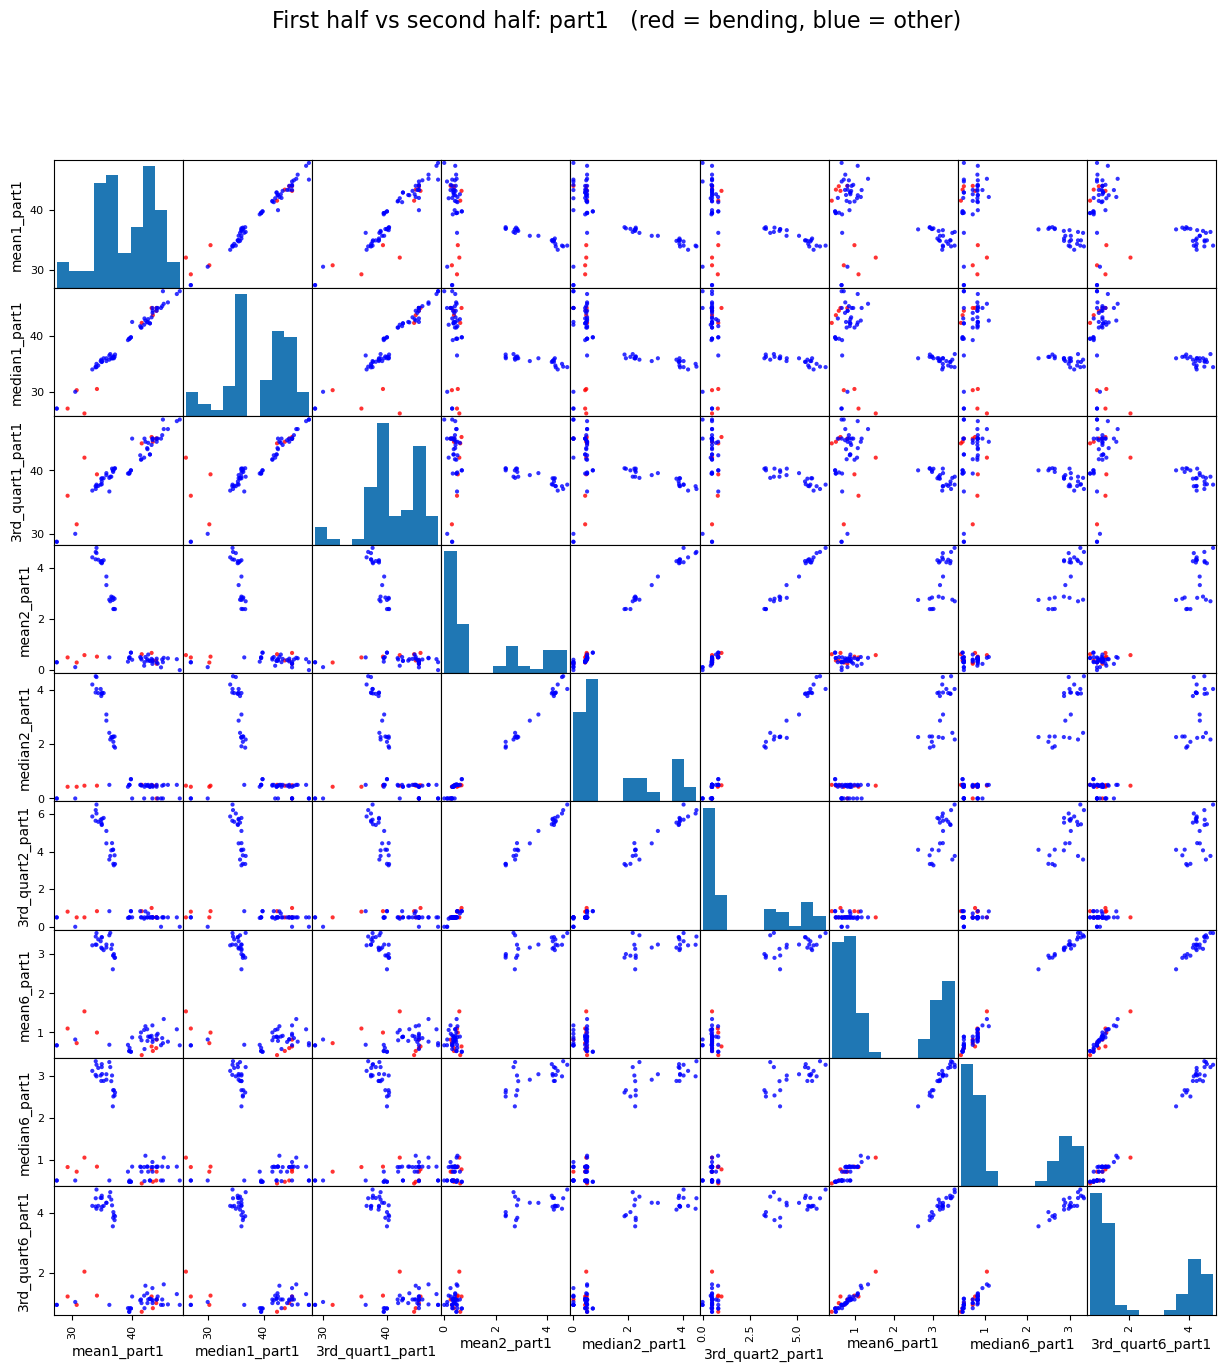

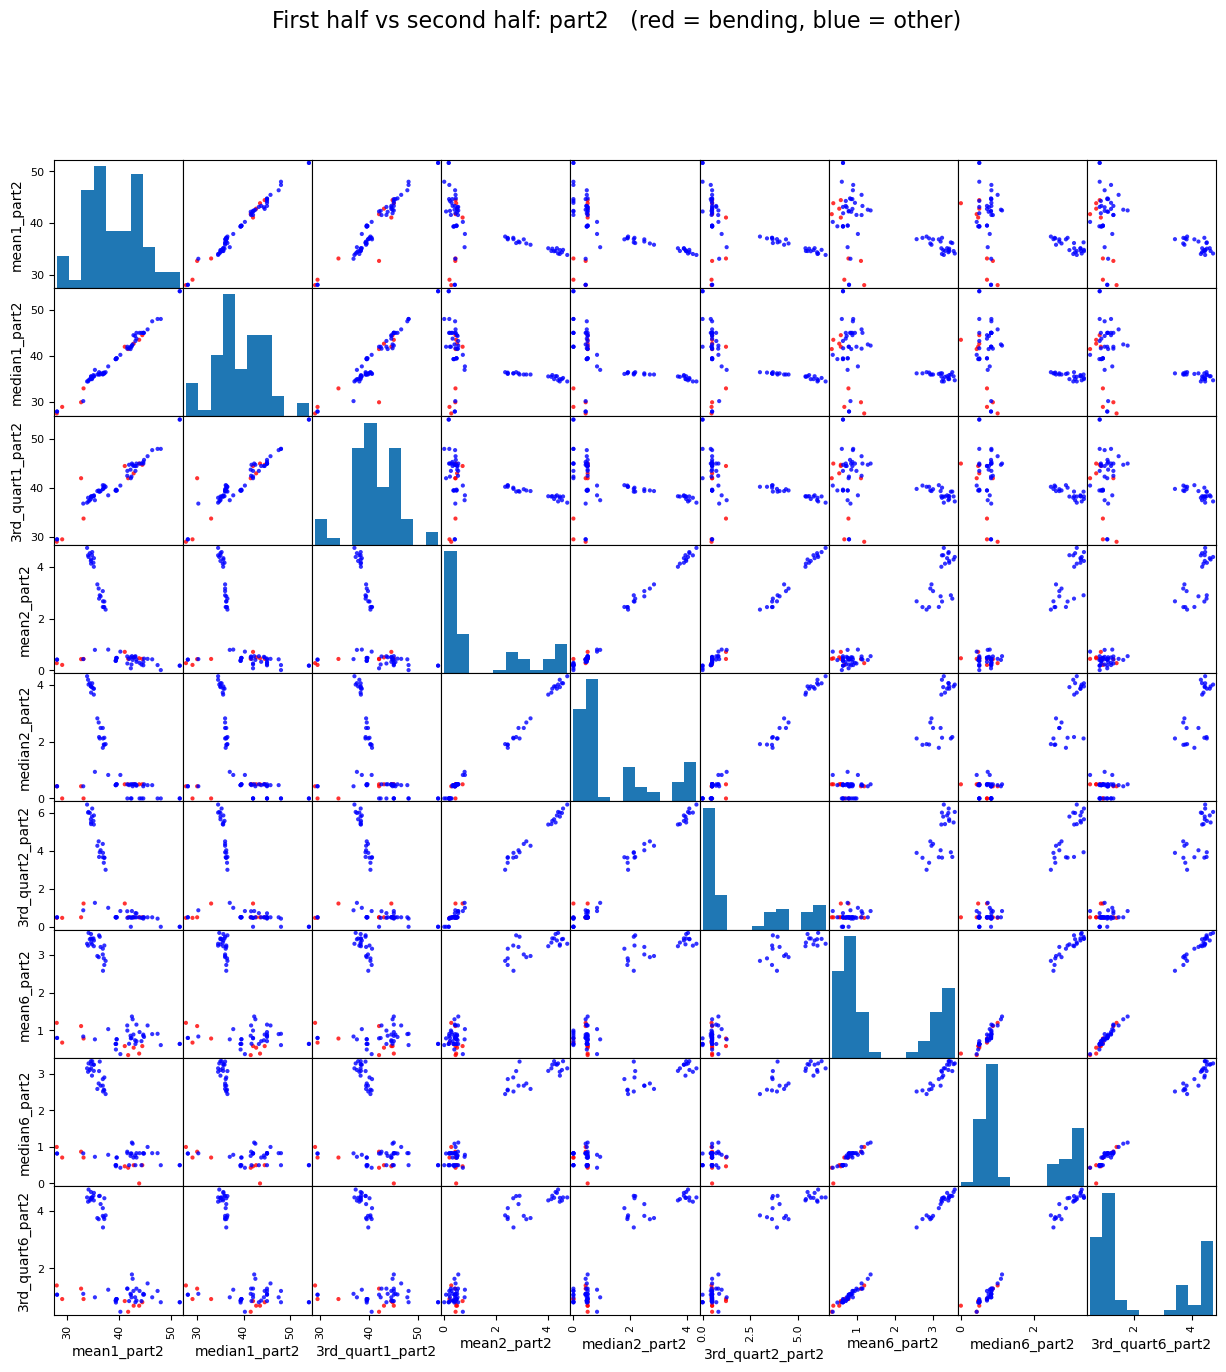

In [6]:
train_features_2 = get_features(train, 2)

for part in ["part1", "part2"]:
    cols = ["mean1_" + part, "median1_" + part, "3rd_quart1_" + part,
            "mean2_" + part, "median2_" + part, "3rd_quart2_" + part,
            "mean6_" + part, "median6_" + part, "3rd_quart6_" + part]

    pd.plotting.scatter_matrix(train_features_2[cols], c=colors, figsize=(15, 15), alpha=0.8, diagonal="hist")
    plt.suptitle("First half vs second half: " + part + "   (red = bending, blue = other)", fontsize=16)
    plt.show()

Splitting each time series into two parts did not create a considerable difference in the scatterplots. The bending and other activity classes remain relatively well separated, although the additional features provide more detail.

#### iii. Time Series Segments

Right vs. Wrong Cross-Validation:

The wrong way is to select features using the entire training set before cross-validation because this causes data leakage. The right way is to perform feature selection within each training fold so the validation data remains unseen.

Stratified Cross-Validation:

I used 5-fold stratified cross-validation to maintain approximately the same proportion of bending and non-bending instances in each fold, since the classes are imbalanced.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)

results = []

for l in range(1, 21):
    features = get_features(train, l)
    X = features.drop(columns="activity")
    y = get_labels(features)

    for p in range(1, 11):
        model = Pipeline([("scale", StandardScaler()),("rfe", RFE(LogisticRegression(C=1e10, max_iter=100), n_features_to_select=p, step=0.1)), ("logreg", LogisticRegression(C=1e10, max_iter=100))])

        acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy").mean()
        results.append([l, p, acc])

results = pd.DataFrame(results, columns=["l", "p", "cv_accuracy"])

display(results.pivot(index="l", columns="p", values="cv_accuracy").round(3))

results_sorted = results.sort_values(by=["cv_accuracy", "l", "p"], ascending=[False, True, True])

print(results_sorted.head(5))

best_l = int(results_sorted.iloc[0]["l"])
best_p = int(results_sorted.iloc[0]["p"])
best_cv_acc = results_sorted.iloc[0]["cv_accuracy"]

print()
print("best l =", best_l, " best p =", best_p, " CV accuracy =", round(best_cv_acc, 4))

features = get_features(train, best_l)
X_train = features.drop(columns="activity")
y_train = get_labels(features)

final_model = Pipeline([("scale", StandardScaler()),("rfe", RFE(LogisticRegression(C=1e10, max_iter=100), n_features_to_select=best_p, step=0.1)), ("logreg", LogisticRegression(C=1e10, max_iter=100))])

final_model.fit(X_train, y_train)

chosen = X_train.columns[final_model.named_steps["rfe"].support_]
print("features kept by RFE:", list(chosen))

p,1,2,3,4,5,6,7,8,9,10
l,,,,,,,,,,
1,0.886,0.855,0.898,0.956,0.970,0.956,0.942,0.942,0.942,0.942
2,0.929,0.898,0.912,0.912,0.898,0.898,0.927,0.913,0.913,0.913
3,0.957,0.971,0.986,0.986,0.986,0.957,0.927,0.927,0.927,0.942
4,0.926,0.942,0.942,0.942,0.942,0.942,0.942,0.942,0.956,0.956
5,0.927,0.927,0.899,0.927,0.927,0.942,0.927,0.942,0.942,0.956
6,0.927,0.956,0.942,0.927,0.942,0.956,0.942,0.942,0.942,0.942
7,0.927,0.899,0.942,0.913,0.942,0.927,0.913,0.927,0.913,0.913
8,0.942,0.884,0.913,0.913,0.898,0.942,0.957,0.929,0.929,0.929
9,0.885,0.885,0.913,0.899,0.927,0.942,0.956,0.956,0.942,0.942


      l   p  cv_accuracy
22    3   3     0.985714
23    3   4     0.985714
24    3   5     0.985714
112  12   3     0.985714
199  20  10     0.985714

best l = 3  best p = 3  CV accuracy = 0.9857
features kept by RFE: ['mean5_part1', '3rd_quart5_part1', '3rd_quart1_part2']


#### iv. Confusion Matrix

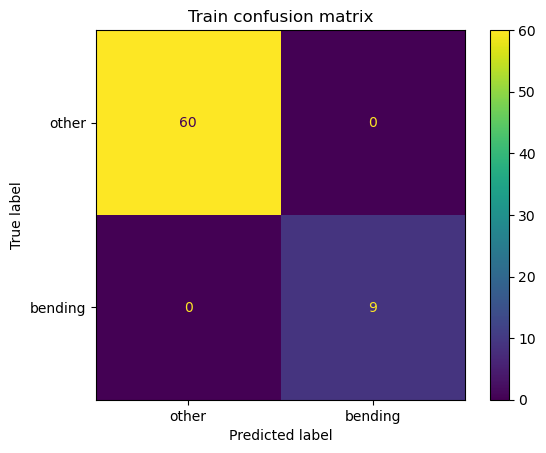

train accuracy: 1.0


In [8]:
pred_train = final_model.predict(X_train)
cm = confusion_matrix(y_train, pred_train)
ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot()
plt.title("Train confusion matrix")
plt.show()

print("train accuracy:", accuracy_score(y_train, pred_train))

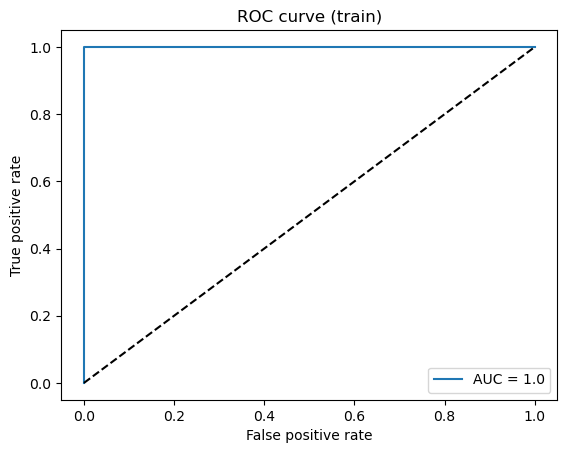

In [9]:
prob_train = final_model.predict_proba(X_train)[:, 1]
fpr, tpr, thresholds = roc_curve(y_train, prob_train)
auc = roc_auc_score(y_train, prob_train)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("ROC curve (train)")
plt.legend()
plt.show()

In [10]:
X_chosen = sm.add_constant(X_train[chosen])
sm_model = sm.Logit(y_train, X_chosen).fit(disp=0)
print(sm_model.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                   69
Model:                          Logit   Df Residuals:                       65
Method:                           MLE   Df Model:                            3
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                   1.000
Time:                        19:53:40   Log-Likelihood:            -1.3772e-08
converged:                      False   LL-Null:                       -26.718
Covariance Type:            nonrobust   LLR p-value:                 1.481e-11
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const              -53.8583   3.89e+07  -1.38e-06      1.000   -7.63e+07    7.63e+07
mean5_part1         14.2053   2.02e+06   7.03e-06      1.000   -3.96e+06    3.96e+06
3rd_quart5_part1     4.9777 

/opt/anaconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.12/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/p

In [11]:
features = get_features(train, best_l)
X_train = features.drop(columns="activity")
y_train = get_labels(features)

final_model = Pipeline([("scale", StandardScaler()),("rfe", RFE(LogisticRegression(C=1e10, max_iter=100), n_features_to_select=best_p, step=0.1)),("logreg", LogisticRegression(C=1e10, max_iter=100)),])
final_model.fit(X_train, y_train)

chosen = X_train.columns[final_model.named_steps["rfe"].support_]
print("features kept by RFE:", list(chosen))


features kept by RFE: ['mean5_part1', '3rd_quart5_part1', '3rd_quart1_part2']


#### v. Test Classifier

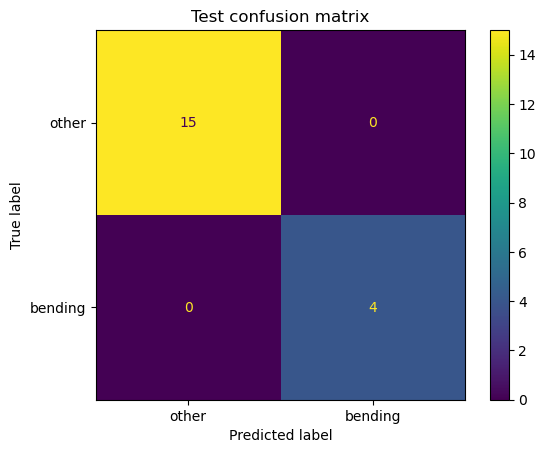

test accuracy: 1.0
cross-validation accuracy: 0.9857


In [12]:
test_features = get_features(test, best_l)
X_test = test_features.drop(columns="activity")
y_test = get_labels(test_features)

pred_test = final_model.predict(X_test)
test_acc = accuracy_score(y_test, pred_test)

cm = confusion_matrix(y_test, pred_test)
ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot()
plt.title("Test confusion matrix")
plt.show()

print("test accuracy:", round(test_acc, 4))
print("cross-validation accuracy:", round(best_cv_acc, 4))

The test accuracy was 100%, slightly higher than the cross-validation accuracy of 98.57%. This suggests that the model performed well on both the training validation folds and the unseen test data.

#### vi. Separation

Yes, the classes appear to be well separated, which causes instability in the logistic regression parameters. The model achieves perfect training accuracy, and the coefficients become very large due to complete separation. This makes the coefficient estimates unreliable.

#### vii. Imbalance

In [13]:
print("bending in train:", sum(y_train == 1))
print("other in train:", sum(y_train == 0))

bending in train: 9
other in train: 60


The classes are imbalanced, with 9 bending instances and 60 other instances. I used case-control sampling to balance the classes by selecting an equal number of bending and non-bending instances. I then adjusted the logistic regression intercept to account for the original class proportions.

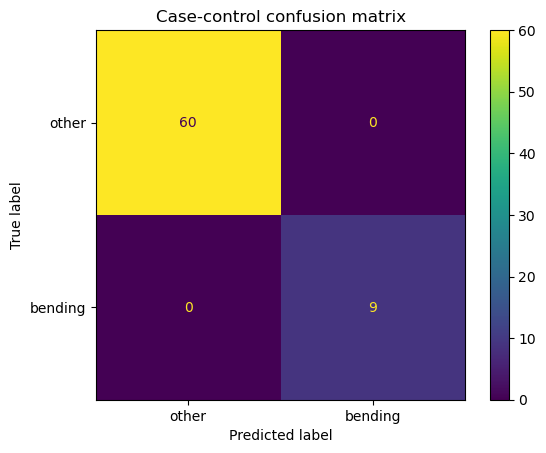

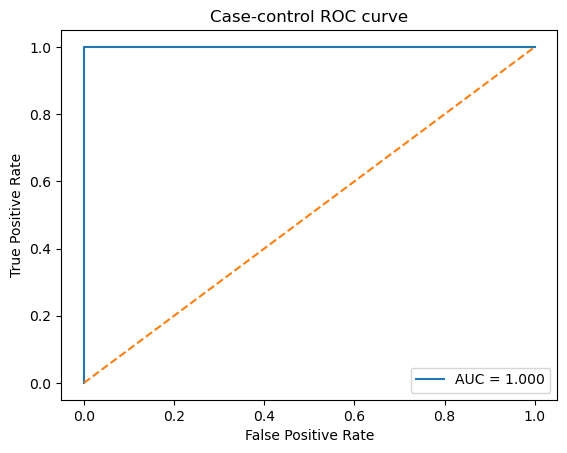

original class counts:
0    60
1     9
Name: count, dtype: int64
balanced sample counts:
0    9
1    9
Name: count, dtype: int64
adjusted intercept: -4.1435
training accuracy: 1.0
training AUC: 1.0


In [14]:
X = X_train[chosen]
y = pd.Series(np.asarray(y_train), index=X.index)

bending = y[y == 1].index
other = y[y == 0].index

rng = np.random.default_rng(0)
other_sample = rng.choice(other, size=len(bending), replace=False)
sample_idx = bending.append(pd.Index(other_sample))

X_sample = X.loc[sample_idx]
y_sample = y.loc[sample_idx]

scaler = StandardScaler()
X_sample_scaled = scaler.fit_transform(X_sample)

model = LogisticRegression(C=1e10, max_iter=100)
model.fit(X_sample_scaled, y_sample)

pi = y.mean()
pi_sample = y_sample.mean()

adjustment = np.log(pi / (1 - pi)) - np.log(pi_sample / (1 - pi_sample))
model.intercept_[0] += adjustment

X_scaled = scaler.transform(X)
y_pred = model.predict(X_scaled)
y_prob = model.predict_proba(X_scaled)[:, 1]

cm = confusion_matrix(y, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot()
plt.title("Case-control confusion matrix")
plt.show()

fpr, tpr, _ = roc_curve(y, y_prob)
auc = roc_auc_score(y, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Case-control ROC curve")
plt.legend()
plt.show()

print("original class counts:")
print(y.value_counts().sort_index())

print("balanced sample counts:")
print(y_sample.value_counts().sort_index())

print("adjusted intercept:", round(model.intercept_[0], 4))
print("training accuracy:", round(accuracy_score(y, y_pred), 4))
print("training AUC:", round(auc, 4))

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

In [15]:
C_values = [0.01, 0.1, 1, 10, 100, 1000]

l1_results = []

for l in range(1, 21):
    features = get_features(train, l)
    X = features.drop(columns="activity")
    y = get_labels(features)

    model = Pipeline([("scale", StandardScaler()),("logreg", LogisticRegression(penalty="l1", solver="liblinear", max_iter=1000)),])
    search = GridSearchCV(model, {"logreg__C": C_values}, cv=cv, scoring="accuracy")
    search.fit(X, y)
    l1_results.append([l, search.best_params_["logreg__C"], search.best_score_])

l1_results = pd.DataFrame(l1_results, columns=["l", "best_C", "cv_accuracy"])
l1_results

,l,best_C,cv_accuracy
0,1,100,0.956044
1,2,10,0.913187
2,3,10,0.970330
3,4,10,0.970330
4,5,1,0.970330
5,6,10,0.970330
6,7,1000,0.956044
7,8,1000,0.956044
8,9,1,0.927473
9,10,1,0.956044


In [16]:

l1_sorted = l1_results.sort_values(by=["cv_accuracy", "l"], ascending=[False, True])
l1_best_l = int(l1_sorted.iloc[0]["l"])
l1_best_C = l1_sorted.iloc[0]["best_C"]
l1_cv_acc = l1_sorted.iloc[0]["cv_accuracy"]
print("best l =", l1_best_l, "  best C =", l1_best_C, "  CV accuracy =", round(l1_cv_acc, 4))

features = get_features(train, l1_best_l)
X_train_l1 = features.drop(columns="activity")
y_train_l1 = get_labels(features)

l1_model = Pipeline([("scale", StandardScaler()),("logreg", LogisticRegression(penalty="l1", solver="liblinear", C=l1_best_C, max_iter=1000)),])
l1_model.fit(X_train_l1, y_train_l1)

coefs = l1_model.named_steps["logreg"].coef_[0]
print("number of features:", len(coefs), "   non-zero coefficients:", sum(coefs != 0))
print("features kept:", list(X_train_l1.columns[coefs != 0]))


best l = 12   best C = 1.0   CV accuracy = 0.9857
number of features: 216    non-zero coefficients: 8
features kept: ['mean5_part2', 'median5_part2', '3rd_quart1_part7', 'mean4_part9', 'median4_part9', 'mean5_part11', 'mean6_part11', 'median4_part12']


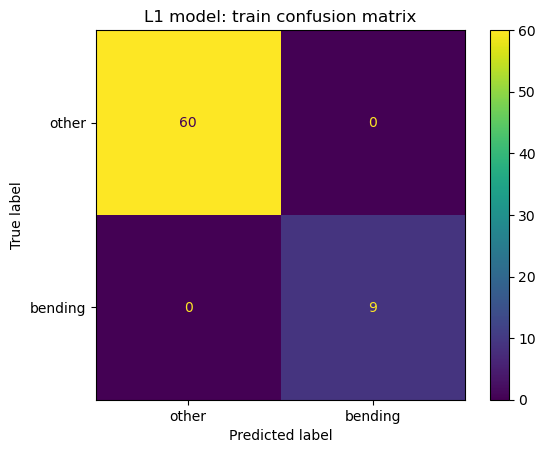

train accuracy: 1.0   AUC: 1.0


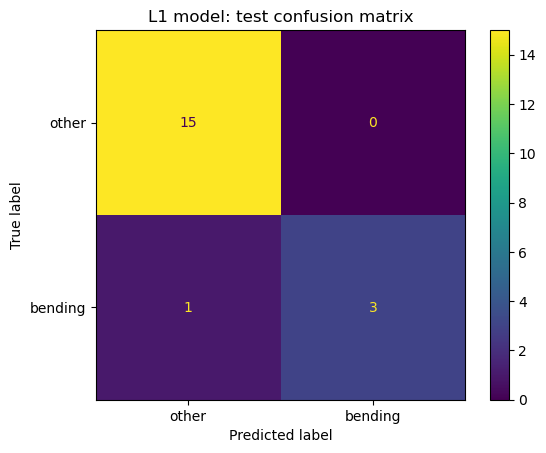

test accuracy: 0.9474   AUC: 0.9833


In [17]:
test_features = get_features(test, l1_best_l)
X_test_l1 = test_features.drop(columns="activity")
y_test_l1 = get_labels(test_features)

for name, X_eval, y_eval in [("train", X_train_l1, y_train_l1), ("test", X_test_l1, y_test_l1)]:
    pred = l1_model.predict(X_eval)
    prob = l1_model.predict_proba(X_eval)[:, 1]
    cm = confusion_matrix(y_eval, pred)
    ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot()
    plt.title("L1 model: " + name + " confusion matrix")
    plt.show()
    print(name, "accuracy:", round(accuracy_score(y_eval, pred), 4), "  AUC:", round(roc_auc_score(y_eval, prob), 4))

#### ii. Comparison

Both methods performed similarly, with a cross-validation accuracy of 98.6%. However, RFE performed slightly better on the test set, achieving 100% accuracy compared to 94.7% for L1-penalized logistic regression.

L1-penalized logistic regression was easier to implement because it automatically selects features through regularization, while RFE requires a separate feature selection process.

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

In [18]:
multi_results = []

for l in range(1, 21):
    features = get_features(train, l)
    X = features.drop(columns="activity")
    y = features["activity"]

    model = Pipeline([("scale", StandardScaler()),("logreg", LogisticRegression(penalty="l1",solver="saga",max_iter=1000,tol=0.01,random_state=0))])

    search = GridSearchCV(model,{"logreg__C": [1, 10, 100]},cv=cv,scoring="accuracy",n_jobs=-1)

    search.fit(X, y)
    multi_results.append([l, search.best_params_["logreg__C"], search.best_score_])

multi_results = pd.DataFrame(multi_results,columns=["l", "best_C", "cv_accuracy"])

multi_results

/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,l,best_C,cv_accuracy
0,1,10,0.868132
1,2,100,0.839560
2,3,10,0.768132
3,4,100,0.782418
4,5,100,0.810989
5,6,10,0.768132
6,7,100,0.812088
7,8,100,0.768132
8,9,10,0.781319
9,10,10,0.751648


In [19]:
best_row = multi_results.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
best_l = int(best_row["l"])
best_C = best_row["best_C"]

train_features = get_features(train, best_l)
test_features = get_features(test, best_l)
X_train_m = train_features.drop(columns="activity")
y_train_m = train_features["activity"]
X_test_m = test_features.drop(columns="activity")
y_test_m = test_features["activity"]

multi_model = Pipeline([("scale", StandardScaler()), ("logreg", LogisticRegression(penalty="l1", solver="saga", C=best_C, max_iter=10000, random_state=0))])
multi_model.fit(X_train_m, y_train_m)
pred = multi_model.predict(X_test_m)

print("best l:", best_l)
print("best C:", best_C)
print("CV accuracy:", round(best_row["cv_accuracy"], 4))
print("test error:", round(1 - accuracy_score(y_test_m, pred), 4))

best l: 1
best C: 10.0
CV accuracy: 0.8681
test error: 0.0526


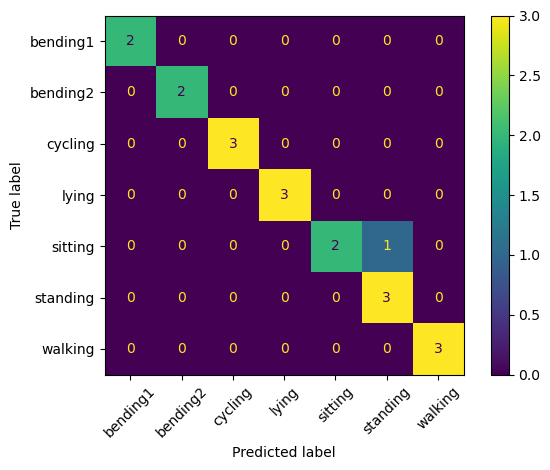

In [20]:
test_features = get_features(test, 1)
X_test = test_features.drop(columns="activity")
y_test = test_features["activity"]

ConfusionMatrixDisplay.from_estimator(multi_model, X_test, y_test, xticks_rotation=45)
plt.tight_layout()
plt.show()

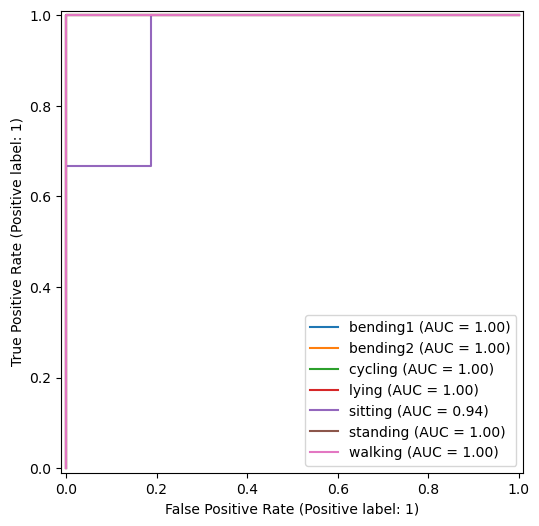

In [21]:
classes = multi_model.classes_
y_binary = label_binarize(y_test, classes=classes)
y_score = multi_model.predict_proba(X_test)

fig, ax = plt.subplots(figsize=(7, 6))
for i, activity in enumerate(classes):
    RocCurveDisplay.from_predictions(y_binary[:, i], y_score[:, i], name=activity, ax=ax)

plt.show()

The multiclass confusion matrix shows the number of correct and incorrect predictions for each activity. The ROC curves use a one-vs-rest approach, treating each activity as the positive class and all other activities as the negative class.

#### ii. Naive Bayes

In [22]:
gaussian_results = []

for l in range(1, 21):
    features = get_features(train, l)
    X = features.drop(columns="activity")
    y = features["activity"]
    acc = cross_val_score(GaussianNB(), X, y, cv=cv, scoring="accuracy", n_jobs=-1).mean()
    gaussian_results.append([l, acc])

gaussian_results = pd.DataFrame(gaussian_results, columns=["l", "cv_accuracy"])
gaussian_results

/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,l,cv_accuracy
0,1,0.840659
1,2,0.738462
2,3,0.708791
3,4,0.724176
4,5,0.680220
5,6,0.726374
6,7,0.695604
7,8,0.681319
8,9,0.752747
9,10,0.738462


In [23]:
best_row = gaussian_results.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
gaussian_l = int(best_row["l"])

train_features = get_features(train, gaussian_l)
test_features = get_features(test, gaussian_l)

X_train_nb = train_features.drop(columns="activity")
y_train_nb = train_features["activity"]
X_test_nb = test_features.drop(columns="activity")
y_test_nb = test_features["activity"]

gaussian_model = GaussianNB()
gaussian_model.fit(X_train_nb, y_train_nb)
pred = gaussian_model.predict(X_test_nb)

gaussian_error = 1 - accuracy_score(y_test_nb, pred)

print("best l:", gaussian_l)
print("CV accuracy:", round(best_row["cv_accuracy"], 4))
print("test error:", round(gaussian_error, 4))

best l: 1
CV accuracy: 0.8407
test error: 0.1053


In [24]:
multinomial_results = []

for l in range(1, 21):
    features = get_features(train, l)
    X = features.drop(columns="activity")
    y = features["activity"]
    model = Pipeline([("scale", MinMaxScaler()), ("nb", MultinomialNB())])
    acc = cross_val_score(model, X, y, cv=cv, scoring="accuracy", n_jobs=-1).mean()
    multinomial_results.append([l, acc])

multinomial_results = pd.DataFrame(multinomial_results, columns=["l", "cv_accuracy"])
multinomial_results

/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/model_selection/_split.py:737: UserWarning: The least populated class in y has only 4 members, which is less than n_splits=5.
  warnings.warn(
/opt/anaconda3/lib/python

,l,cv_accuracy
0,1,0.607692
1,2,0.650549
2,3,0.621978
3,4,0.621978
4,5,0.650549
5,6,0.650549
6,7,0.664835
7,8,0.650549
8,9,0.636264
9,10,0.636264


In [25]:
best_row = multinomial_results.sort_values(["cv_accuracy", "l"], ascending=[False, True]).iloc[0]
multinomial_l = int(best_row["l"])

train_features = get_features(train, multinomial_l)
test_features = get_features(test, multinomial_l)

X_train_nb = train_features.drop(columns="activity")
y_train_nb = train_features["activity"]
X_test_nb = test_features.drop(columns="activity")
y_test_nb = test_features["activity"]

multinomial_model = Pipeline([("scale", MinMaxScaler()), ("nb", MultinomialNB())])
multinomial_model.fit(X_train_nb, y_train_nb)
pred = multinomial_model.predict(X_test_nb)

multinomial_error = 1 - accuracy_score(y_test_nb, pred)

print("best l:", multinomial_l)
print("CV accuracy:", round(best_row["cv_accuracy"], 4))
print("test error:", round(multinomial_error, 4))

best l: 7
CV accuracy: 0.6648
test error: 0.1579


#### ii. Comparison

L1 logistic regression performed best among the three methods, with the lowest test error of 5.26% and the highest cross-validation accuracy of 86.81%. Gaussian Naive Bayes was the second-best method, with a test error of 10.53% and a cross-validation accuracy of 84.07%. Multinomial Naive Bayes performed the worst, with the highest test error of 15.79% and the lowest cross-validation accuracy of 66.48%.

L1 logistic regression likely performed better because it uses L1 regularization to select important features and reduce the influence of less useful ones. Gaussian Naive Bayes also performed reasonably well because it assumes features follow a Gaussian distribution, which may be more suitable for the continuous time-series features in this dataset. Multinomial Naive Bayes is generally better suited for count-based data, which may explain its lower accuracy.

Overall, L1 logistic regression is the best choice for this multiclass classification problem because it achieved the lowest test error and the highest cross-validation accuracy.

## 3. ISLR 4.8.3

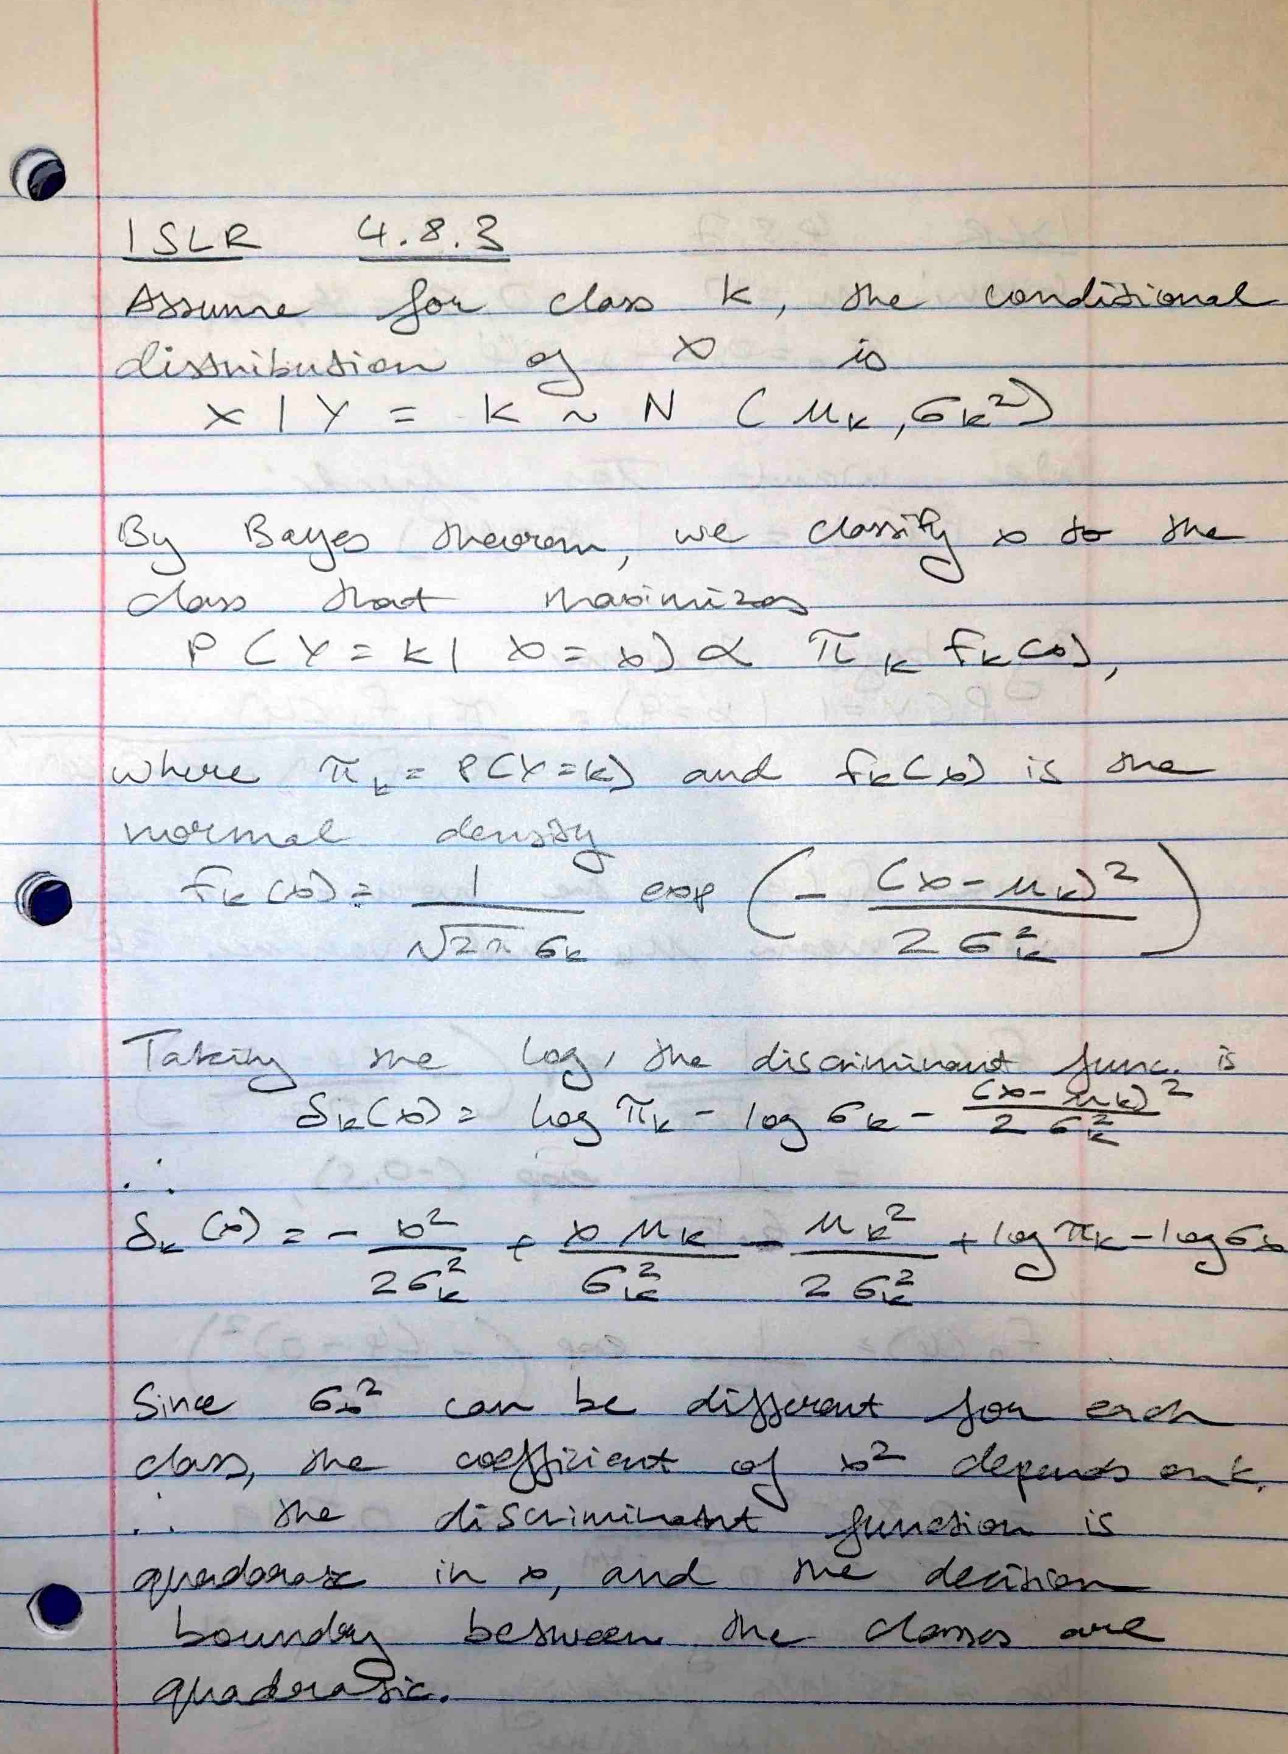

## 4. ISLR 4.8.7

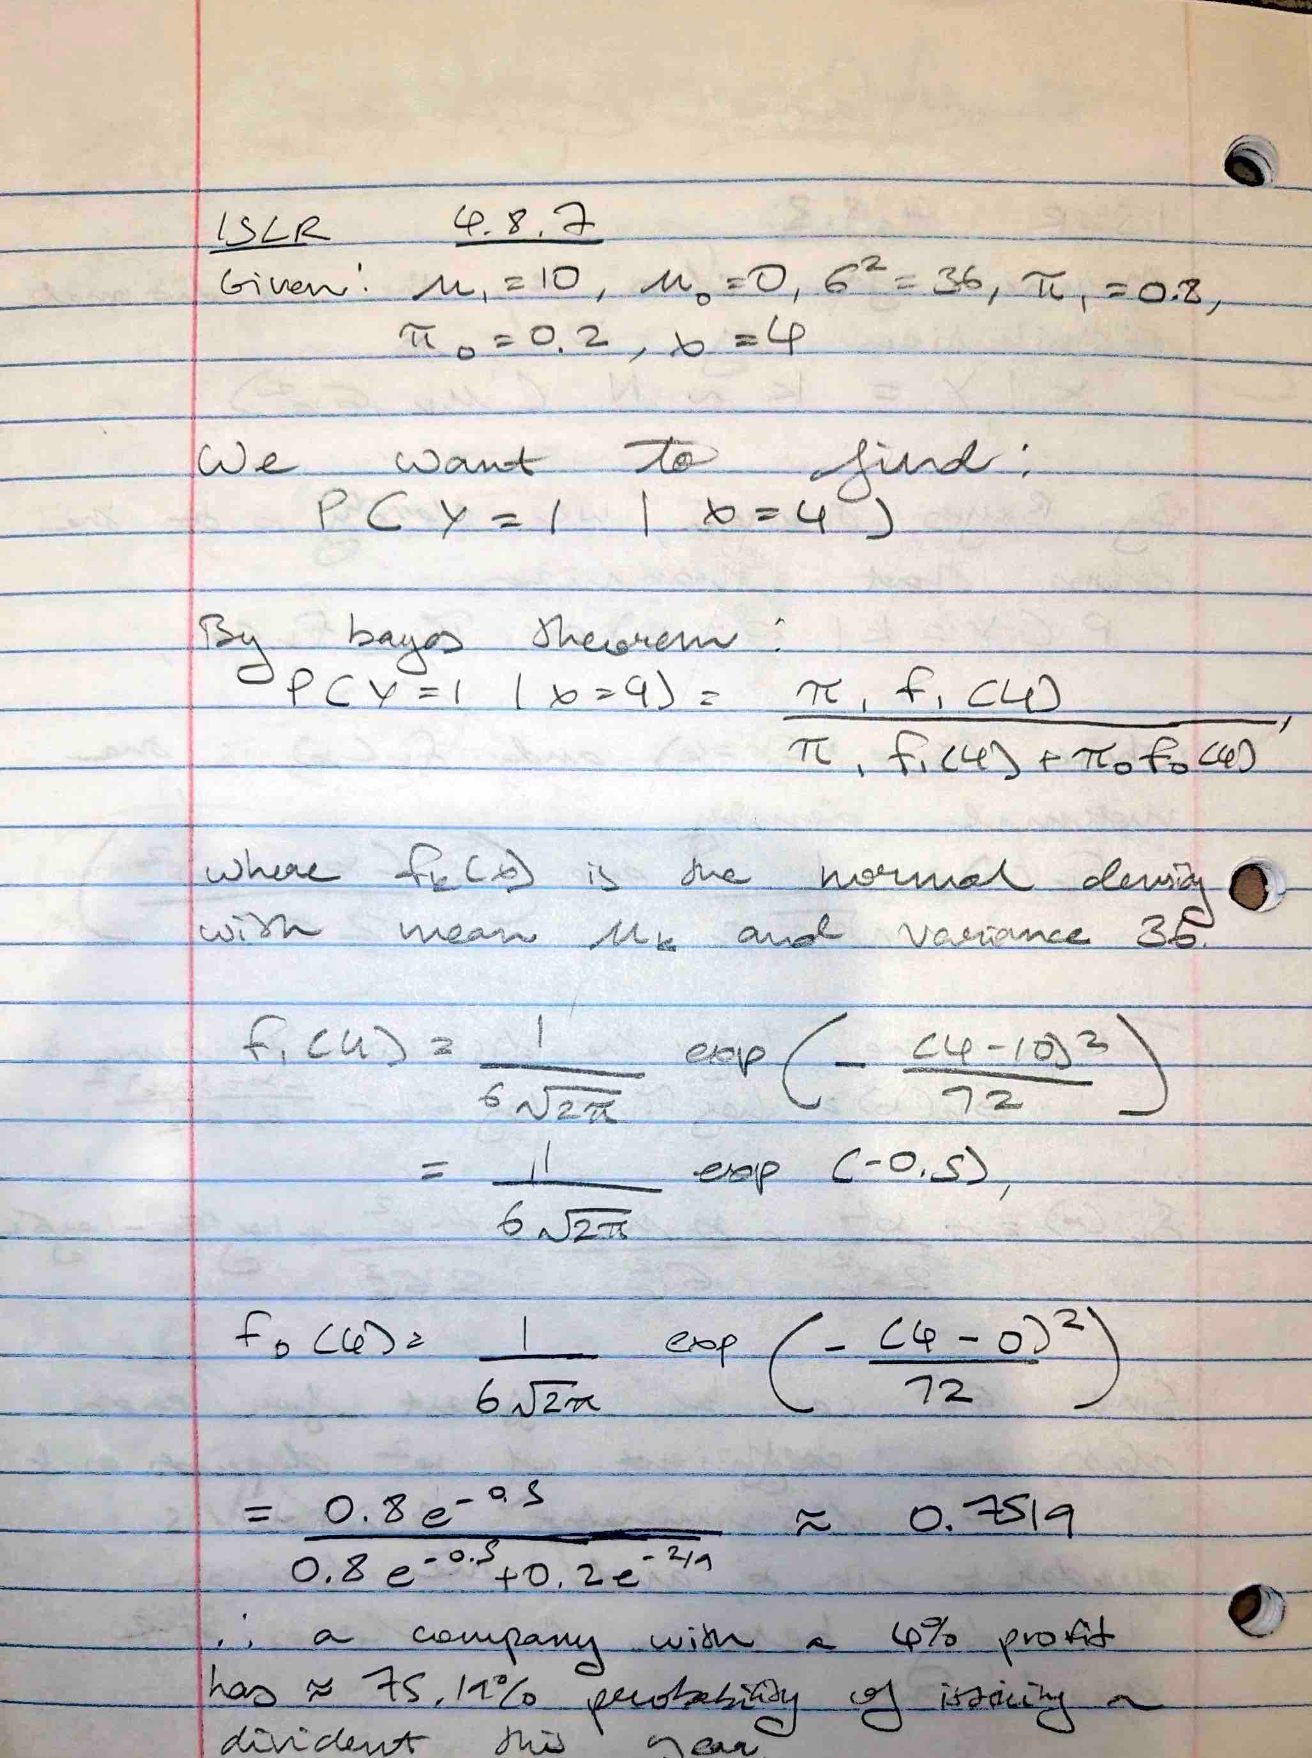